# **Ejercicios de PIAC**

Recopilación de los ejercicios de los notebooks del curso, ordenados por tema.

### Contenidos

1. [Problemas QUBO y modelo Ising](#tema1)
1. [Computación cuántica adiabática y Quantum Annealing](#tema2)
1. [Algoritmo cuántico de optimización aproximada (QAOA)](#tema3)
1. [Algoritmo cuántico variacional para el cálculo de autovalores (VQE)](#tema4)
1. [Efecto del ruido y barren plateaus](#tema5)

<a name="tema1"></a>
# **Tema 1: Problemas QUBO y modelo Ising**

Notebook: `01 - Problemas QUBO y modelo Ising.ipynb`

<a name="ejercicio1"></a>
## **Ejercicio 1**

Para el grafo de la imagen, obtén la formulación analítica del problema MAXCUT en formato Ising, realizando el cambio de variables a partir de la formulación QUBO, y resuélvelo por fuerza bruta usando Qiskit (crea el Hamiltoniano y obtén la energía de todos los estados). Indica también cómo obtener el peso del corte.

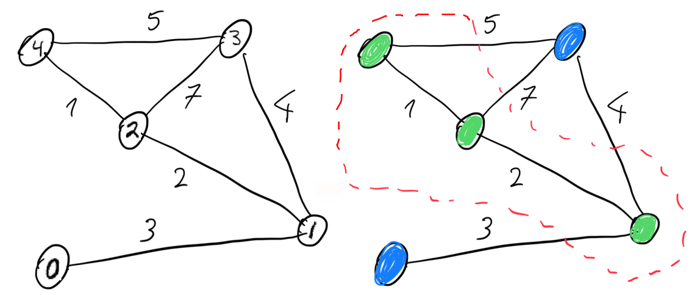


---

<a name="ejercicio2"></a>
## **Ejercicio 2**:

Problema de la [**suma de subconjuntos**](https://en.wikipedia.org/wiki/Subset_sum_problem) (*subset sum*): dado un conjunto de enteros $S = \{s_i\}$ y un entero $T$, ¿existe un subconjunto de $S$ cuya suma sea igual a $T$?

Se trata de un problema importante en la teoría de la complejidad y en la criptografía. Se sabe que es NP-completo.

Escribe en formato QUBO el problema para $S=\{-3, 2, -2, 5, 1\}$ y $T=-4$. Igual que antes, obtén la fórmula analítica del problema en formato Ising (haciendo el cambio de variable) y resuélvelo por fuerza bruta usando Qiskit (crea el Hamiltoniano y obtén la energía de todos los estados).

---

<a name="tema2"></a>
# **Tema 2: Computación cuántica adiabática y Quantum Annealing**

Notebook: `02 - Computación cuántica adiabática y Quantum Annealing.ipynb`

<a name="ejercicio3"></a>
## **Ejercicio 3**

Comprobad que el modelo BQM obtenido coincide con el ejemplo de programación binaria lineal que vimos en el tema anterior, y que expresaba el problema con restricciones en formato QUBO como sigue:


\begin{aligned}
\text{Minimizar} \quad & -5x_0+3x_1+-2x_2+P(x_0+x_2+s_0-1)^2+P(3x_0-x_1+3x_2+s_{11}+2s_{12}+2s_{13}-4)^2 \\
 & \text{con }x_i,s_i = \{0,1\}
\end{aligned}


con $P=11$.

Podéis usar herramientas como [Wolframalpha](https://www.wolframalpha.com/) para hacer la expansión.



---

<a name="ejercicio4"></a>
## **Ejercicio 4**: reparto de turnos de trabajo


En nuestra empresa se trabaja en cuatro turnos horarios, numerados del 0 al 3. Mediante una encuesta, se ha solicitado a los empleados que valoren de 1 a 4 su preferencia de turno (1 indica la más preferida y 4 la menos preferida). Los resultados son los de la tabla:

| Empleado  | Turno 0 | Turno 1 | Turno 2 | Turno 3 |
|-----------|---------|---------|---------|---------|
| Ana       | 1       | 2       | 3       | 4       |
| Benito    | 3       | 2       | 1       | 4       |
| Carlos    | 4       | 2       | 3       | 1       |
| Diana     | 4       | 1       | 2       | 3       |
| Enrique   | 1       | 2       | 3       | 4       |
| Fabio     | 3       | 2       | 1       | 4       |
| Gala      | 4       | 2       | 3       | 1       |
| Hugo      | 4       | 1       | 2       | 3       |


Queremos expresar el problema como un CQM y resolverlo por fuerza bruta usando el ExactCQMSolver (usaríamos el LeapHybridCQMSampler si tuviésemos acceso a Leap).

El modelo que vamos a definir considera un conjunto de variables binarias $x_{et}$ con $e \in {\text{empleados}}$ y $t \in \{0,1,2,3\}$ representa el turno. Si $x_{et} = 1$ el empleado $e$ se asigna al turno $t$. Notar que varios empleados pueden asignarse al mismo turno, pero cada empleado solo puede estar en un turno, es decir:

$$
\sum_{t=0}^3 x_{et} = 1, ∀ e
$$

La función a minimizar será la siguiente:

$$
\sum_{e \in {\text{empleados}}}\sum_{t=0}^3 \text{preferencia}_{et}x_{et}
$$



**Apartado 1**

En este primer caso, la única restricción es que cada empleado solo puede estar asignado a un turno.

Mira la función `build_cqm()` para añadir esa restricción para cada empleado.

Sugerencia: mira la función [`cqm.add_discrete`](https://docs.dwavequantum.com/en/latest/ocean/api_ref_dimod/generated/dimod.ConstrainedQuadraticModel.add_discrete.html#dimod-constrainedquadraticmodel-add-discrete), que permite indicar que para un empleado $e$ solo haya un 1 en $x_{et}, \forall t\in\{0,1,2,3\}$

In [ ]:
# TODO: Añade los imports necesarios


# Devuelve el sampler que vamos a usar
def set_sampler():
    '''Devuelve un sampler'''
    # TODO: especifica un sampler
    sampler =

    return sampler

# Empleados y preferencias
def employee_preferences():
    '''Devuelve un diccionario de empleados y sus preferencias'''

    preferences = { "Ana": [1,2,3,4],
                    "Benito": [3,2,1,4],
                    "Carlos": [4,2,3,1],
                    "Diana": [4,1,2,3],
                    "Enrique": [1,2,3,4],
                    "Fabio": [3,2,1,4],
                    "Gala": [4,2,3,1],
                    "Hugo": [4,1,2,3]}

    return preferences

# Crea y devuelve el modelo CQM
def build_cqm():
    '''Construye el CQM de nuestro problema'''

    preferences = employee_preferences()
    num_shifts = 4

    # TODO: Inicializa el objeto cqm
    cqm =

    # Recorre los nombres de los empleados y sus preferencias
    for employee, preference in preferences.items():
        # Crea etiquetas de la forma x_et para cada turno
        labels = [f"{employee}_{shift}" for shift in range(num_shifts)]

        # TODO: Añade las variables binarias al modelo
        cqm.

        # TODO: Añade la restricción de que cada empleado solo esté en un turno
        # usando cqm.add_discrete
        cqm.

        # Crea una lista [(labels, preferencia)]
        # por ejemplo: [('x_Ana_0', 1), ('x_Ana_1', 2), ('x_Ana_2', 3), ('x_Ana_3', 4)]
        # y la añade a la función objetivo
        cqm.objective.add_linear_from([*zip(labels, preference)])

    return cqm

# Resuelve el problema
def solve_problem(cqm, sampler):
    '''Resuelve en CQM usando el sampler'''

    # Obtiene el sampler
    sampler = set_sampler()

    # TODO: Resuelve el CQM usando el sampler
    sampleset =

    # TODO Filtra para quedarte con las soluciones factibles
    feasible_sampleset =

    return feasible_sampleset

# Procesa la solución
def process_sampleset(sampleset):
    '''Procesa y muestra la mejor solución encontrada'''

    # Obtén la primera solución
    sample = sampleset.first.sample

    shift_schedule=[ [] for i in range(4) ]

    # Obtiene una lista con el/los empleados asignados a cada turno
    for key, val in sample.items():
        if val == 1.0:
            name = key.split('_')[0]
            shift = int(key.split('_')[1])
            shift_schedule[shift].append(name)

    return shift_schedule

# Ejecuta el programa
shifts = [0, 1, 2, 3]
num_shifts = len(shifts)

cqm = build_cqm()

# Imprime el modelo
print('=========================================================================')
print(cqm)
print('=========================================================================')

sampler = set_sampler()

sampleset = solve_problem(cqm, sampler)

shift_schedule = process_sampleset(sampleset)

print('\nSolución')
for i in range(num_shifts):
    print("Turno:", shifts[i], "\tEmpleado(s): ", shift_schedule[i])

**Apartado 2**

Ahora queremos añadir las siguientes restricciones

1. Benito y Fabio no pueden trabajar durante el mismo turno
2. A Enrique y Hugo les gustaría trabajar en el mismo turno

Modifica la función `build_cqm()` para incorporar esas restricciones

In [ ]:
# TODO: Añade los imports necesarios


# Devuelve el sampler que vamos a usar
def set_sampler():
    '''Devuelve un sampler'''
    # TODO: especifica un sampler
    sampler =

    return sampler

# Empleados y preferencias
def employee_preferences():
    '''Devuelve un diccionario de empleados y sus preferencias'''

    preferences = { "Ana": [1,2,3,4],
                    "Benito": [3,2,1,4],
                    "Carlos": [4,2,3,1],
                    "Diana": [4,1,2,3],
                    "Enrique": [1,2,3,4],
                    "Fabio": [3,2,1,4],
                    "Gala": [4,2,3,1],
                    "Hugo": [4,1,2,3]}

    return preferences

# Crea y devuelve el modelo CQM
def build_cqm():
    '''Construye el CQM de nuestro problema con más restricciones'''

    preferences = employee_preferences()
    num_shifts = 4

    # TODO: Inicializa el objeto cqm
    cqm =

    # Recorre los nombres de los empleados y sus preferencias
    for employee, preference in preferences.items():
        # Crea etiquetas de la forma x_et para cada turno
        labels = [f"{employee}_{shift}" for shift in range(num_shifts)]

        # TODO: Añade las variables binarias al modelo
        cqm.

        # TODO: Añade la restricción de que cada empleado solo esté en un turno
        # usando cqm.add_discrete
        cqm.

        # Crea una lista [(labels, preferencia)]
        # por ejemplo: [('x_Ana_0', 1), ('x_Ana_1', 2), ('x_Ana_2', 3), ('x_Ana_3', 4)]
        # y la añade a la función objetivo
        cqm.objective.add_linear_from([*zip(labels, preference)])

    # TODO: Añade la restricción 1
    # Queremos penalizar que x_{Benito}{t} = x_{Fabio}{t} = 1, para algún t



    # TODO: Añade la restricción 2
    # En este caso, queremos que x_{Enrique}{t} = x_{Hugo}{t} = 1, para algún t
    # Es decir, queremos penalizar los casos x_{Enrique}{t} != x_{Hugo}{t}



    return cqm

# Resuelve el problema
def solve_problem(cqm, sampler):
    '''Resuelve en CQM usando el sampler'''

    # Obtiene el sampler
    sampler = set_sampler()

    # TODO: Resuelve el CQM usando el sampler
    sampleset =

    # TODO Filtra para quedarte con las soluciones factibles
    feasible_sampleset =

    return feasible_sampleset

# Procesa la solución
def process_sampleset(sampleset):
    '''Procesa y muestra la mejor solución encontrada'''

    # Obtén la primera solución
    sample = sampleset.first.sample

    shift_schedule=[ [] for i in range(4)]

    # Obtiene una lista con el/los empleados asignados a cada turno
    for key, val in sample.items():
        if val == 1.0:
            name = key.split('_')[0]
            shift = int(key.split('_')[1])
            shift_schedule[shift].append(name)

    return shift_schedule

# Ejecuta el programa
shifts = [0, 1, 2, 3]
num_shifts = len(shifts)

cqm = build_cqm()

# Imprime el modelo
print('=========================================================================')
print(cqm)
print('=========================================================================')

sampler = set_sampler()

sampleset = solve_problem(cqm, sampler)

shift_schedule = process_sampleset(sampleset)

print('\nSolución')
for i in range(num_shifts):
    print("Turno:", shifts[i], "\tEmpleado(s): ", shift_schedule[i])

**Apartado 3**

Modifica el código anterior para añadir dos nuevas restricciones:

1. Ana no puede trabajar en el turno 0
2. Tiene que haber un máximo de dos empleados por turno

---

<a name="tema3"></a>
# **Tema 3: Algoritmo cuántico de optimización aproximada (QAOA)**

Notebook: `03 - Algoritmo cuántico de optimización aproximada (QAOA).ipynb`

<a name="ejercicio5"></a>
## **Ejercicio 5**:


En el ejercicio 2, habíamos expresado como QUBO el problema de la suma de subconjuntos para $S=\{-3, 2, -2, 5, 1\}$ y $T=4$. Resuélvelo usando QAOA:

a) Creando el circuito como un QAOAAnsatz y utilizando la función de minimización de Scipy

b) Usando la implementación de QAOA de qiskit_algorithms


---

<a name="ejercicio6"></a>
## **Ejercicio 6**:

**MAXCUT** como problema QCQP

Hemos visto cómo expresar el problema MAXCUT como un QUBO (forma $f(x) = x^TQx$). Es también posible expresarlo como un problema QCQP de variables binarias:

$$
f(x) = c^T x + x^T A x
$$

siendo $A$ la matriz de adyacencias del grafo.

a. Obtén la expresión para el vector $c$

b. Haz una función que reciba una matriz de adyacencias de un grafo no dirigido (como un array de numpy) y resuelva el problema MAXCUT usando el módulo de optimización de Qiskit
   - La función debe verificar que la matriz es una matriz de adyacencias correcta.


---

<a name="tema4"></a>
# **Tema 4: Algoritmo cuántico variacional para el cálculo de autovalores (VQE)**

Notebook: `04 - Algoritmo cuántico variacional para el cálculo de autovalores (VQE).ipynb`

<a name="ejercicio7"></a>
## **Ejercicio 7: el problema del viajante de comercio**.

El Problema del Viajante de Comercio (_Travelling Salesman Problem_, TSP) es un problema clásico de optimización combinatoria. Consiste en encontrar la ruta más corta que permita a un viajante visitar un conjunto de ciudades exactamente una vez cada una y regresar al punto de partida.

A cada par de ciudades se le asigna un coste de viaje (distancia, tiempo, energía, etc.), y el objetivo es determinar el recorrido de coste total mínimo.

Desde el punto de vista computacional, el TSP es un problema NP-hard, lo que implica que no se conoce un algoritmo eficiente que encuentre siempre la solución óptima en tiempo polinómico para instancias grandes.

El TSP es fundamental en áreas como logística, planificación de rutas, diseño de circuitos electrónicos, bioinformática y optimización industrial, y constituye uno de los ejemplos más ilustrativos de los retos y técnicas utilizadas en la optimización discreta.

El TSP puede modelarse de manera natural mediante la teoría de grafos. Cada ciudad se representa como un nodo de un grafo y cada posible conexión entre dos ciudades se modela como una arista con un peso, que corresponde al coste de viajar entre ellas (distancia, tiempo, coste económico, etc.).

Si el viajante puede viajar en ambas direcciones entre dos ciudades con el mismo coste, se emplea un grafo no dirigido y ponderado. Si los costes difieren según la dirección del viaje, el modelo es un grafo dirigido y ponderado.

En este marco, el TSP consiste en encontrar un ciclo hamiltoniano de coste mínimo dentro del grafo. Un ciclo hamiltoniano es un camino cerrado que visita cada nodo exactamente una vez y vuelve al punto de inicio.


Supongamos el grafo $G=(V,E)$ con $n=|V|$ nodos y distancias (pesos) $w_{ij}$. Un ciclo hamiltoniano se describe mediante $n^2$ variables binarias $x_{i,p}$ que cumplen:

$$
x_{i,p} =
\begin{cases}
1 & \text{si la ciudad } i\in\{0,\dots,n-1\} \text{ ocupa la posición } p\in\{0,\dots,n-1\},\\
0 & \text{en otro caso.}
\end{cases}
$$


La función objetivo a minimizar es:

$$
C(x) = \sum_{i,j=0}^{n-1}  w_{ij}
\sum_{p=0}^{n-1} \; x_{i,p} \; x_{j,(p+1)\bmod n}
$$


#### Restricciones

1. En cada paso $p$ solo podemos estar en una ciudad (vértice), es decir:

$$
\sum_{i=0}^{n-1} x_{i,p} = 1, \quad \forall p=0,\dots,n-1
$$

2. Cada ciudad se visita una y solo una vez, es decir:

$$
\sum_{p=0}^{n-1} x_{i,p} = 1, \quad \forall i=0,\dots,n-1
$$

Vamos a suponer que el grafo está totalmente conectado (hay rutas entre todas las ciudades). Si no es así, necesitamos una restricción adicional que evite las rutas no disponibles.


La función objetivo incluyendo las restricciones queda:


$$
\mathcal{f}(x) = \sum_{i,j=0}^{n-1}  w_{ij}
\sum_{p=0}^{n-1} \; x_{i,p} \; x_{j,(p+1)\bmod n}
+ A \sum_{p=0}^{n-1} \left(1 - \sum_{i=0}^{n-1} x_{i,p} \right)^2
+ A \sum_{i=0}^{n-1} \left(1 - \sum_{p=0}^{n-1} x_{i,p} \right)^2
$$

donde $A$ debe ser lo suficientemente grande para forzar a que se cumplan las restricciones, por ejemplo, que $A \gt \max{(w_{ij})}$.

## Problema TSP en Qiskit

El [TSP](https://qiskit-community.github.io/qiskit-optimization/stubs/qiskit_optimization.applications.Tsp.html) también está disponible en [`qiskit_optimization.applications`](https://qiskit-community.github.io/qiskit-optimization/apidocs/qiskit_optimization.applications.html).

In [ ]:
import networkx as nx
import numpy as np
import matplotlib as plt
from qiskit_optimization.applications import Tsp

n = 4
tsp = Tsp.create_random_instance(n, seed=5365)
G = tsp.graph

adj_matrix = nx.to_numpy_array(G)
print("Distancias\n", adj_matrix)

# Mostramos el grafo
layout = nx.random_layout(G,seed=10)
colors = ["r" for node in tsp.graph.nodes]
nx.draw_networkx(G, layout, node_color=colors)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos=layout, edge_labels=labels);

El siguiente código encuentra la mejor ruta probando todas:

In [ ]:
from itertools import permutations

# El punto de partida siempre es el 0
def brute_force_tsp(w, N):
  # Obtiene todas las permutaciones (posibles rutas) entre 1 y n-1
  # El 0 se considera punto de partida
  a = list(permutations(range(1, N)))
  last_best_distance = 1e10
  # Recorremos cada posible ruta
  for i in a:
    distance = 0
    pre_j = 0
    order = (0,) + i
    # Acumulamos las distancias entre las ciudades
    for j in i:
      distance = distance + w[j, pre_j]
      pre_j = j
    # Sumamos la distancia de la última ciudad al 0
    distance = distance + w[pre_j, 0]
    # Nos quedamos con la menor distancia
    if distance < last_best_distance:
      best_order = order
      last_best_distance = distance
  return last_best_distance, best_order


best_distance, best_order = brute_force_tsp(adj_matrix, n)
print(
  "Mejor ruta por fuerza bruta = {}, con distancia total = {}".format(
  best_order,
  best_distance)
)

**EJERCICIO**:

Resuelve el problema usando SamplingVQE y un ansatz [`n-local`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.n_local) con puertas $R_y$ como puertas de rotación y Z controladas como bloques de entrelazamiento.

  - Obtén la distancia a partir de la energía y el offset
  - Usa `tsp.interpret()` para obtener la ruta solución a partir del autoestado más probable (que puedes obtener usando `tsp.sample_most_likely`).


Obtén también el mínimo autovalor usando un minimizador clásico, como `NumPyMinimumEigensolver` para comparar el resultado.


---

<a name="tema5"></a>
# **Tema 5: Efecto del ruido y barren plateaus**

Notebook: `05 - Efecto del ruido y barren plateaus.ipynb`

<a name="ejercicio8"></a>
## **Ejercicio 8: QAOA con ruido**

Repetimos el Ejemplo 2 del notebook de QAOA, minimizando el Hamiltoniano:

$$
H_c = 3Z_2Z_0 - Z_2Z_1 + 2Z_0
$$

pero sustituyendo las primitivas ideales (`StatevectorEstimator`, `StatevectorSampler`) por las de Qiskit Aer (`EstimatorV2`, `SamplerV2`) con un modelo de ruido. Ambas tienen la misma interfaz, por lo que las funciones `cost_func_estimator` y `circuit_sampler` no cambian.

 (a) Implementa dicha optimización usando un ruido diseñado con los errores que consideres. Compara el efecto del ruido con el ideal bajo distintas opciones de shots y distintos números de capas del circuito de QAOA. ¿Qué pasa al aumentar el número de capas del QAOA en simulación ideal? ¿Y en simulación ruidosa?

 (b) Elige un FakeBackend y repite el experimento anterior.

 (c) Ejecútalo en un equipo real de IBM

---

<a name="ejercicio9"></a>
## **Ejercicio 9: *barren plateaus* según el ansatz, la profundidad y la función de coste**

En el ejemplo de *barren plateaus* del notebook vimos el efecto del ruido. Ahora, **sin ruido**, vamos a estudiar cómo decae la varianza del gradiente $\text{Var}_{\boldsymbol\theta}[\partial_0 C]$ al aumentar el número de cúbits $n$, con parámetros aleatorios uniformes en $[0, 2\pi)$, para distintos ansätze, profundidades y funciones de coste.

Usa la función `varianza_gradiente` del ejemplo del notebook con un `EstimatorV2` de Aer sin modelo de ruido y con `default_precision=0` (valores esperados exactos, sin ruido de muestreo).

**Funciones de coste:**

- **Local:** $H = \sum_{i=0}^{n-1} Z_i Z_{i+1}$ (modelo de Ising en anillo, con $Z_n \equiv Z_0$).
- **Global:** $H = Z^{\otimes n}$.

**Ansätze** (de la [librería de circuitos de Qiskit](https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_library)), con $L$ = `reps` capas:

- `real_amplitudes(n, entanglement="linear", reps=L)`
- `efficient_su2(n, entanglement="linear", reps=L)`
- `n_local(n, rotation_blocks="ry", entanglement_blocks=[], reps=L)`: rotaciones $R_y$ sin entrelazamiento.

(a) Calcula $\text{Var}[\partial_0 C]$ para $n = 2, 4, \dots, 12$ y $L \in \{1, 4, 16\}$, con 200 muestras, para los 3 ansätze y las 2 funciones de coste. Represéntala frente a $n$ en escala semilogarítmica junto con la recta de referencia $2^{-n}$.

(b) Ajusta $\log_2 \text{Var} \approx \text{cte} - \alpha\, n$ (con `np.polyfit`, usando $n \ge 4$), es decir, $\text{Var} \sim 2^{-\alpha n}$, y obtén $\alpha$ para cada caso. $\alpha \approx 0$ indica que no hay *barren plateau* y $\alpha > 0$ que sí lo hay (con $b = 2^{\alpha}$).

(c) Responde a las siguientes cuestiones:

1. ¿Qué influye más en la aparición del *barren plateau*: el ansatz, la profundidad o la función de coste?
2. Para el ansatz de rotaciones $R_y$ sin entrelazamiento y el coste global, calcula analíticamente $\langle Z^{\otimes n}\rangle$ y $\text{Var}[\partial_0 C]$, y compáralo con la simulación.
3. Con el coste local, ¿cómo cambia $\alpha$ con la profundidad $L$ en `real_amplitudes` y `efficient_su2`? Relaciónalo con los resultados de Cerezo et al. ([arXiv:2001.00550](https://arxiv.org/abs/2001.00550)).
4. El ansatz de rotaciones $R_y$ sin entrelazamiento con coste local no presenta *barren plateau*. ¿Es un buen ansatz para un VQE? ¿Por qué?
5. Si $\alpha \approx 1$, ¿cuántos *shots* harían falta, aproximadamente, para estimar el gradiente con $n = 50$ cúbits?

(d) (Opcional) Repite el cálculo derivando respecto a un parámetro de una capa intermedia (argumento `k` de `varianza_gradiente`). ¿Cambia el resultado?

---